# Vestiaire · les indicateurs en Python

Ce carnet calcule les repères affichés dans le prototype Vestiaire :

1. la **charge** de chaque séance (note de difficulté × durée, ou sRPE) ;
2. le **ratio aigu / chronique** (charge des 7 derniers jours comparée aux 4 semaines précédentes) ;
3. la **monotonie** et la **contrainte** de la semaine ;
4. la **forme du jour**, comparée à la moyenne personnelle de chaque joueuse ;
5. le **statut du jour** (en forme, à surveiller, alerte) avec son explication ;
6. les **zones de vitesse féminines** pour les fichiers GPS.

Les données de la partie 1 sont **fictives** (effectif « Seniors F » du prototype).
La partie 2 rejoue les mêmes calculs sur les données ouvertes **SoccerMon** (deux équipes féminines norvégiennes, 2020-2021).

> Ces indicateurs sont des repères pour le staff, pas un diagnostic ni une prédiction de blessure.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import vestiaire_metrics as vm
from vestiaire_metrics.demo import generer, EFFECTIF

pd.set_option("display.precision", 2)
pd.set_option("display.max_colwidth", None)
BLEU_NUIT, TURQUOISE, VERT, ORANGE, ROUGE, GRIS = "#0B1F3A", "#1EC8B0", "#177A43", "#A35F00", "#C62E2E", "#9AA8B8"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})

## Partie 1 · Effectif fictif

### Les données d'entrée

Deux tableaux suffisent : les séances (note de difficulté de 0 à 10 et durée) et les états du jour (5 questions notées de 1 à 5).

In [2]:
seances, etats, douleurs = generer(fin="2026-10-13")
print(f"{len(seances)} séances, {len(etats)} états du jour, {seances.joueuse.nunique()} joueuses")
seances.head()

602 séances, 837 états du jour, 12 joueuses


,joueuse,date,rpe,duree_min
0,Camille D.,2026-08-06,6.0,73.0
1,Camille D.,2026-08-07,4.0,63.0
2,Camille D.,2026-08-08,7.0,86.0
3,Camille D.,2026-08-10,4.0,57.0
4,Camille D.,2026-08-11,7.0,92.0


In [3]:
etats.head()

,joueuse,date,fatigue,sommeil,courbatures,stress,humeur
0,Camille D.,2026-08-05,4.0,4.0,4.0,4.0,5.0
1,Camille D.,2026-08-06,4.0,4.0,4.0,4.0,4.0
2,Camille D.,2026-08-07,4.0,3.0,3.0,3.0,4.0
3,Camille D.,2026-08-08,4.0,4.0,3.0,4.0,4.0
4,Camille D.,2026-08-09,4.0,3.0,4.0,4.0,4.0


### Charge quotidienne

Une ligne par jour, une colonne par joueuse. Les jours sans séance valent 0 : c'est indispensable pour que les moyennes sur 7 et 28 jours aient un sens.

In [4]:
quotidien = vm.charge_quotidienne(seances)
quotidien.tail(7).round(0)

joueuse,Camille D.,Chloé P.,Emma G.,Inès B.,Jade T.,Lina A.,Léa M.,Manon V.,Maëlys R.,Nina L.,Sarah K.,Zoé F.
date,,,,,,,,,,,,
2026-10-07,0.0,0.0,0.0,720.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-08,456.0,408.0,345.0,594.0,234.0,483.0,504.0,456.0,345.0,414.0,511.0,546.0
2026-10-09,180.0,177.0,240.0,240.0,61.0,183.0,240.0,228.0,114.0,228.0,240.0,112.0
2026-10-10,602.0,616.0,980.0,855.0,516.0,696.0,679.0,744.0,630.0,623.0,696.0,752.0
2026-10-11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-12,180.0,177.0,183.0,237.0,59.0,180.0,305.0,189.0,189.0,171.0,232.0,122.0
2026-10-13,630.0,752.0,637.0,708.0,376.0,696.0,688.0,720.0,696.0,588.0,564.0,492.0


### L'écran « Effectif du jour »

On combine charge et forme pour obtenir le statut de chaque joueuse et la phrase « Pourquoi ».

In [5]:
jour = quotidien.index.max()
charge = vm.resume_charge(quotidien, jour)
ref = vm.reference_personnelle(etats)
forme_jour = (ref[ref.date == jour].set_index("joueuse")[["forme", "moyenne_perso"]]
              .reindex(charge.index))
statut = vm.statut_du_jour(charge, forme_jour, douleurs, vm.Reperes(ratio_min=0.8, ratio_max=1.3))

effectif = (statut.join(forme_jour).join(charge[["charge_7j", "ratio"]])
            .assign(poste=lambda d: d.index.map(EFFECTIF)))
effectif[["poste", "statut", "forme", "moyenne_perso", "charge_7j", "ratio", "pourquoi"]]

,poste,statut,forme,moyenne_perso,charge_7j,ratio,pourquoi
joueuse,,,,,,,
Camille D.,Défenseure,alerte,12.0,19.32,2048.0,0.96,Douleur déclarée ce matin · Forme à 12/25 contre 19 habituellement
Inès B.,Milieu,a_surveiller,20.0,17.00,3354.0,1.38,"Ratio aigu / chronique à 1,38, au-dessus de 1,30 · Charge en hausse de 38 % sur ses 4 semaines précédentes"
Sarah K.,Attaquante,a_surveiller,11.0,17.00,2243.0,1.06,Forme à 11/25 contre 17 habituellement
Chloé P.,Attaquante,ok,17.0,18.79,2130.0,0.95,—
Emma G.,Milieu,ok,17.0,16.64,2385.0,1.10,—
Jade T.,Gardienne,ok,NaN,NaN,1246.0,0.80,État du jour pas encore reçu
Lina A.,Défenseure,ok,NaN,NaN,2238.0,0.99,État du jour pas encore reçu
Léa M.,Milieu,ok,20.0,18.07,2416.0,1.10,—
Manon V.,Attaquante,ok,17.0,17.04,2337.0,1.12,—


### Fiche d'Inès B. : la charge par semaine

La dernière barre (7 derniers jours) est comparée à la moyenne de ses 4 semaines précédentes, en pointillé.

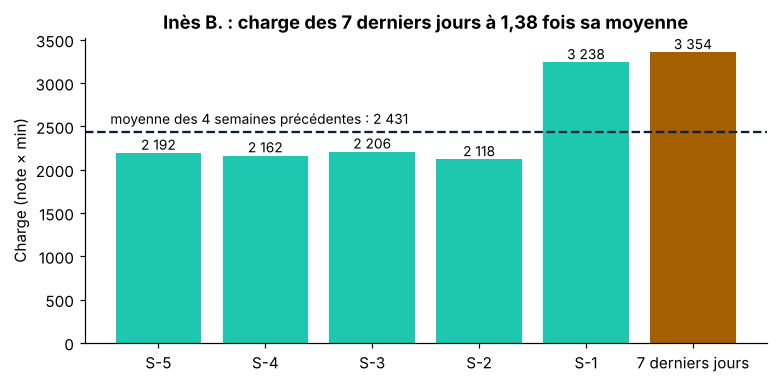

In [6]:
j = "Inès B."
s = quotidien[j]
fin = s.index.max()
semaines = [s.loc[fin - pd.Timedelta(days=7 * (k + 1) - 1): fin - pd.Timedelta(days=7 * k)].sum() for k in range(6)][::-1]
etiquettes = [f"S-{k}" for k in range(5, 0, -1)] + ["7 derniers jours"]
moy4 = sum(semaines[1:5]) / 4

fig, ax = plt.subplots(figsize=(8, 3.6))
couleurs = [TURQUOISE] * 5 + [ORANGE if semaines[-1] / moy4 > 1.3 else TURQUOISE]
ax.bar(etiquettes, semaines, color=couleurs)
ax.axhline(moy4, ls="--", color=BLEU_NUIT, lw=1.5)
ax.text(-0.45, moy4 + 60, f"moyenne des 4 semaines précédentes : {moy4:,.0f}".replace(",", " "), va="bottom", ha="left", fontsize=9)
for x, v in enumerate(semaines):
    ax.text(x, v, f"{v:,.0f}".replace(",", " "), ha="center", va="bottom", fontsize=9)
ratio_txt = f"{semaines[-1] / moy4:.2f}".replace(".", ",")
ax.set_title(f"{j} : charge des 7 derniers jours à {ratio_txt} fois sa moyenne")
ax.set_ylabel("Charge (note × min)")
plt.show()

### Trois façons de calculer le ratio aigu / chronique

Vestiaire affiche la méthode **découplée** (7 derniers jours contre les 28 jours d'avant), la plus simple à expliquer à un staff. La méthode **EWMA** (moyennes exponentielles, Williams et al. 2017) réagit plus vite mais oscille selon le jour de la semaine. Toutes sont disponibles dans le module.

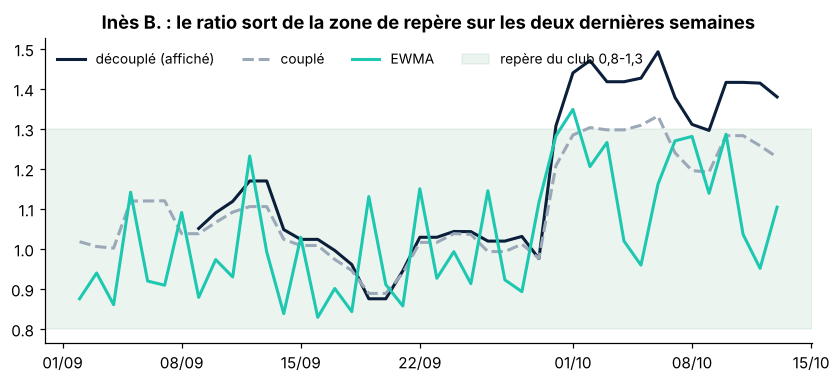

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for methode, nom, couleur, ls in [("decouple", "découplé (affiché)", BLEU_NUIT, "-"), ("couple", "couplé", GRIS, "--"), ("ewma", "EWMA", TURQUOISE, "-")]:
    ax.plot(vm.ratio_aigu_chronique(quotidien, methode)[j], label=nom, color=couleur, ls=ls, lw=2)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.axhspan(0.8, 1.3, color=VERT, alpha=0.08, label="repère du club 0,8-1,3")
ax.set_title(f"{j} : le ratio sort de la zone de repère sur les deux dernières semaines")
ax.legend(frameon=False, ncol=4, fontsize=9)
plt.show()

### Fiche de Camille D. : la forme comparée à sa propre moyenne

La référence est la moyenne de ses 28 jours précédents, sans compter le jour même. Une baisse de 3 points ou plus déclenche « à surveiller ».

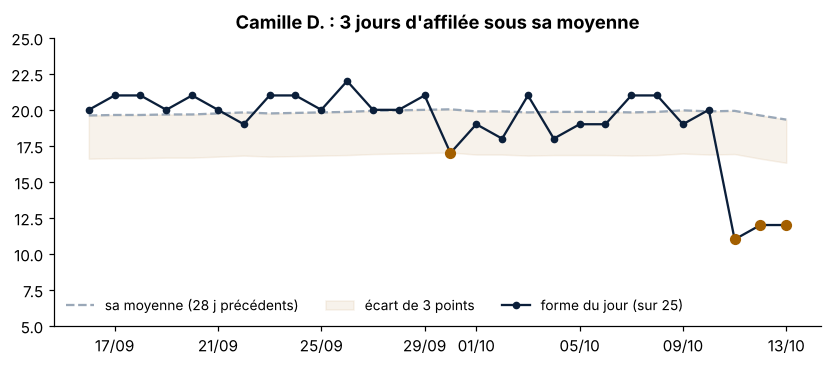

In [8]:
c = ref[ref.joueuse == "Camille D."].set_index("date").tail(28)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(c.index, c.moyenne_perso, color=GRIS, ls="--", label="sa moyenne (28 j précédents)")
ax.fill_between(c.index, c.moyenne_perso - 3, c.moyenne_perso, color=ORANGE, alpha=0.08, label="écart de 3 points")
ax.plot(c.index, c.forme, color=BLEU_NUIT, marker="o", ms=4, lw=1.5, label="forme du jour (sur 25)")
bas = c[c.ecart_points <= -3]
ax.scatter(bas.index, bas.forme, color=ORANGE, zorder=3, s=40)
ax.set_title(f"Camille D. : {vm.jours_sous_moyenne(ref).get('Camille D.')} jours d'affilée sous sa moyenne")
ax.legend(frameon=False, fontsize=9, ncol=3, loc="lower left")
ax.set_ylim(5, 25)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
plt.show()

### Monotonie et contrainte de la semaine

Une monotonie au-dessus de 2 signale une semaine où toutes les séances se ressemblent, sans vraie journée légère.

In [9]:
pd.DataFrame({"monotonie": vm.monotonie(quotidien).iloc[-1],
              "contrainte": vm.contrainte(quotidien).iloc[-1]}).sort_values("contrainte", ascending=False).round(2)

,monotonie,contrainte
joueuse,,
Inès B.,1.62,5442.82
Léa M.,1.28,3104.06
Sarah K.,1.25,2814.93
Manon V.,1.15,2693.51
Lina A.,1.14,2546.88
Emma G.,1.03,2460.21
Nina L.,1.21,2444.30
Camille D.,1.18,2409.57
Chloé P.,1.11,2364.48


### Zones de vitesse : seuils féminins contre masculins

Une trace GPS fictive de 90 minutes à 10 Hz, analysée deux fois. Avec les seuils masculins, une partie des sprints et des accélérations hautes disparaît : c'est exactement l'effet décrit par SkillCorner.

In [10]:
import numpy as np
rng = np.random.default_rng(3)
HZ, v, cur = 10, [], 0.0
while len(v) < 90 * 60 * HZ:                        # 90 minutes d'efforts enchaînés
    cible = rng.choice([1, 4, 8, 12, 16, 20, 24.5], p=[.2, .3, .25, .12, .07, .04, .02]) + rng.normal(0, 1)
    acc = rng.uniform(1.0, 3.6) * 3.6                # accélération en km/h par seconde
    while abs(cur - cible) > acc / HZ:               # montée ou freinage progressif
        cur += np.sign(cible - cur) * acc / HZ
        v.append(cur)
    v.extend([cur] * int(rng.uniform(2, 12) * HZ))  # effort tenu quelques secondes
trace = pd.DataFrame({"vitesse_kmh": np.clip(v, 0, None)})

comparaison = pd.DataFrame({"Seuils féminins": vm.resume_gps(trace, vm.FEMININS),
                            "Seuils masculins": vm.resume_gps(trace, vm.MASCULINS)})
comparaison.round(1)

,Seuils féminins,Seuils masculins
distance_m,10447.2,10447.2
distance_course_m,1974.9,1786.1
distance_hsr_m,946.5,693.4
distance_sprint_m,382.0,75.4
nb_sprints,9.0,2.0
nb_acc_hautes,20.0,10.0
nb_dec_hautes,11.0,4.0
vitesse_pointe_kmh,26.9,26.9


## Partie 2 · Valider sur SoccerMon

Le jeu de données est sur [osf.io/uryz9](https://osf.io/uryz9/) (licence CC-BY 4.0). Une fois les fichiers téléchargés et décompressés :

1. indiquer le dossier des données subjectives dans `DOSSIER` ci-dessous ;
2. vérifier les noms des indicateurs avec `lister_indicateurs` ;
3. relancer les cellules.

L'objectif : retrouver avec notre code les valeurs de charge et de ratio déjà calculées dans SoccerMon, puis regarder si le statut « à surveiller » apparaît autour des blessures déclarées, **sans en faire une prédiction**.

In [11]:
from vestiaire_metrics import soccermon

DOSSIER = None   # par exemple "/Users/julie/Data/SoccerMon/subjective"

if DOSSIER is None:
    print("Indiquez le dossier SoccerMon dans DOSSIER pour lancer cette partie.")
else:
    print(soccermon.lister_indicateurs(DOSSIER))

Indiquez le dossier SoccerMon dans DOSSIER pour lancer cette partie.


In [12]:
if DOSSIER is not None:
    sm = soccermon.charger_dossier(DOSSIER)
    seances_sm = soccermon.vers_seances_vestiaire(sm, col_rpe="rpe", col_duree="duration")
    quotidien_sm = vm.charge_quotidienne(seances_sm)
    ratio_sm = vm.ratio_aigu_chronique(quotidien_sm, "couple")

    # Comparaison avec le ratio fourni par SoccerMon, s'il existe
    if "acwr" in sm:
        fourni = sm.pivot_table(index="date", columns="joueuse", values="acwr")
        a, b = ratio_sm.stack(), fourni.stack()
        commun = a.index.intersection(b.index)
        print(f"Corrélation avec l'ACWR de SoccerMon : {a[commun].corr(b[commun]):.2f} sur {len(commun)} jours-joueuses")

    etats_sm = soccermon.vers_etats_vestiaire(sm)
    ref_sm = vm.reference_personnelle(etats_sm)
    print(ref_sm.groupby("joueuse").forme.describe().round(1).head())

## Limites à garder en tête

- La charge sRPE dépend de l'honnêteté et de la régularité des saisies : l'écran affiche le taux de saisie à côté de chaque indicateur.
- Le ratio aigu / chronique est un repère de variation de charge, débattu dans la littérature. Il ne prédit pas une blessure, et Vestiaire ne le présente jamais ainsi.
- La forme est toujours comparée à la joueuse elle-même : un 17/25 n'a pas le même sens pour toutes.
- Les seuils (ratio, écart de forme, zones de vitesse) sont réglables par chaque club.